# 01-4. 결빙 기상 조건과 검증 지점

01(데이터 탐색)의 6~10장. 모든 RWIS에 가장 가까운 AWS·ASOS 기상을 붙여 결빙이 나타나는 기상 조건을 보고,
두 겨울 비교, 기온감률, 사례, 검증 지점과 이웃 관측소의 관계를 분석한다.

01 구성: 01-1 이론(0장) · 01-2 자료 구성·품질(1~3장) · 01-3 노면온도·노면상태(4~5장) · **01-4 결빙 기상 조건·검증 지점(6~10장)** · 01-5 도로·지형·목표안개(11~12장) · 01-6 이론 검증 Ⅰ(13-1~13-4) · 01-7 이론 검증 Ⅱ·정리(13-5~14장)

- 입력: 01-2의 분석용 자료, 01-3의 관측소 쌍별 통계 (`data/interim/`)
- 출력: RWIS + 최근접 AWS·ASOS 결합 자료(`rwis_weather.parquet`), 시각별 기온감률(`lapse_rates.parquet`) → 01-6·01-7에서 사용

**목차**

6. 결빙이 나타나는 기상 조건
7. 두 겨울 비교와 기상 현상
8. 기온감률 (표고와 기온)
9. 사례 분석: 2025-01-27 ~ 29
10. 검증 지점 분석

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import warnings

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from scipy.spatial.distance import cdist

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# 한글 글꼴 (설치된 것 중 먼저 찾은 것)
for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=PALETTE),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
ROUTE_COLORS = {"서해안": PALETTE[0], "호남선": PALETTE[1], "통영-대전중부선": PALETTE[2]}
INK, MUTED = "#0b0b0b", "#898781"
HOLDOUT = list(config.HOLDOUT_STATIONS)
CRS = 5179

In [3]:
# 01-2(3-6)에서 저장한 분석용 자료와 01-3(4-7)의 관측소 쌍별 통계
rwis = pd.read_parquet(config.INTERIM_DIR / "rwis.parquet")
asos = pd.read_parquet(config.INTERIM_DIR / "asos.parquet")
aws = pd.read_parquet(config.INTERIM_DIR / "aws.parquet")
rwis_st, asos_st, aws_st = (pd.read_parquet(config.INTERIM_DIR / f"stations_{s}.parquet") for s in ["rwis", "asos", "aws"])
pairs = pd.read_parquet(config.INTERIM_DIR / "rwis_pairs.parquet")


def to_points(df, lon="경도", lat="위도"):
    return gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df[lon], df[lat]), crs=4326).to_crs(CRS)


xy = lambda g: np.c_[g.geometry.x, g.geometry.y]

rwis_pt, asos_pt, aws_pt = (to_points(d) for d in (rwis_st, asos_st, aws_st))
st_info = rwis_st.set_index("stn")

# 앞 노트북과 같은 방법으로 다시 만드는 값
aws_vars = [c for c in aws.columns[5:21]]
aws_clean = aws[aws_vars].mask(aws[aws_vars] <= -99)  # AWS 결측 코드 -99.x (01-2의 3-2)
aws_t = aws.assign(ta=aws_clean["1분 평균 기온(°C)"]).pivot(index="time", columns="stn", values="ta")  # (01-2의 3-5)
D_ra = cdist(xy(rwis_pt), xy(aws_pt)) / 1000  # RWIS-AWS 거리 (km, 01-2의 2-4)
D_rs = cdist(xy(rwis_pt), xy(asos_pt)) / 1000  # RWIS-ASOS 거리
nn_asos = dict(zip(rwis_pt["stn"], asos_pt["stn"].values[D_rs.argmin(1)]))  # 최근접 ASOS (01-3의 4-3)
ice_by_day = rwis[rwis["ice"] == 1].groupby("date")["stn"].nunique()  # 날짜별 Ice 관측 RWIS 수 (01-3의 4-4)
print("RWIS:", rwis.shape, "/ AWS:", aws.shape, "/ ASOS:", asos.shape)

RWIS: (587445, 37) / AWS: (1152144, 23) / ASOS: (57600, 32)


## 6. 결빙이 나타나는 기상 조건

목표(결빙) 관측소는 기상 요소를 관측하지 않으므로, 모든 RWIS에 **가장 가까운 AWS(10분)와 ASOS(1시간)** 값을 붙여 비교한다.
산 정상(설천봉)과 섬 지점(말도, 어청도, 선유도, 위도)은 고속도로 환경과 달라 후보에서 뺀다.

### 6-1. 주변 기상 자료 연결

In [4]:
EXCLUDE_AWS = [314, 300, 700, 719, 756]
D_ra2 = D_ra.copy()
D_ra2[:, aws_pt["stn"].isin(EXCLUDE_AWS).to_numpy()] = np.inf
nn_aws = dict(zip(rwis_pt["stn"], aws_pt["stn"].values[D_ra2.argmin(1)]))
match = pd.DataFrame({"지점명": rwis_pt["지점명"].values,
                      "AWS": [aws_st.set_index("stn").loc[nn_aws[s], "지점명"] for s in rwis_pt["stn"]],
                      "AWS 거리(km)": D_ra2.min(1),
                      "ASOS": [asos_st.set_index("stn").loc[nn_asos[s], "지점명"] for s in rwis_pt["stn"]],
                      "ASOS 거리(km)": D_rs.min(1)}, index=rwis_pt["stn"].values)
match.round(1)

,지점명,AWS,AWS 거리(km),ASOS,ASOS 거리(km)
12103,군산휴(도),함라,9.1,군산,3.5
12209,서김제(도),김제,4.4,부안,16.1
12210,부안고려청자휴(도),줄포,11.8,부안,6.4
12211,고인돌휴(도),줄포,12.8,고창군,4.7
12409,우곡3교(도),함라,9.0,군산,6.1
12410,부곡교(도),줄포,8.0,부안,9.6
23202,여산휴(도),여산,4.0,전주,23.0
23203,삼례졸음(도),익산,7.4,전주,9.6
23204,정읍휴(도),태인,8.6,정읍,4.6
23402,해전(도),익산,7.3,전주,8.6


In [5]:
AWS_COLS = {"1분 평균 기온(°C)": "aws_ta", "이슬점온도(°C)": "aws_td", "1분 평균 상대습도(%)": "aws_rh",
            "10분 평균 풍속(m/s)": "aws_ws", "10분 평균 풍향(degree)": "aws_wd", "강수감지(0-무강수)": "aws_rain",
            "12시간 누적 강수량(mm)": "aws_pr12h"}
aws_sel = aws[["stn", "time"]].join(aws_clean[list(AWS_COLS)].rename(columns=AWS_COLS))
m = rwis.assign(aws_stn=rwis["stn"].map(nn_aws), asos_stn=rwis["stn"].map(nn_asos), thour=rwis["time"].dt.floor("h"))
m = m.merge(aws_sel.rename(columns={"stn": "aws_stn"}), on=["aws_stn", "time"], how="left")
asos_sel = asos[["stn", "time", "전운량(10분위)", "적설(cm)"]].rename(
    columns={"stn": "asos_stn", "time": "thour", "전운량(10분위)": "cloud", "적설(cm)": "snow"})
m = m.merge(asos_sel, on=["asos_stn", "thour"], how="left")
m["snow"] = m["snow"].fillna(0)
m = m.sort_values(["stn", "time"]).reset_index(drop=True)
for hours in [3, 12, 24]:
    m[f"강수시간{hours}h"] = m.groupby("stn")["aws_rain"].transform(lambda s: s.rolling(6 * hours, min_periods=1).sum() / 6)


def hours_since(flag):
    step = np.arange(len(flag), dtype=float)
    last = pd.Series(np.where(flag, step, np.nan)).ffill().to_numpy()
    return (step - last) / 6


m["강수후경과h"] = m.groupby("stn")["aws_rain"].transform(lambda s: pd.Series(hours_since((s >= 1).to_numpy()), index=s.index))
m["노면-이슬점"] = m["rst"] - m["aws_td"]
m["is_ice"] = m["state"] == 4
m["cold_dry"] = (m["state"] != 4) & m["state"].notna() & (m["rst"] <= 0)
print(m.shape, "기상값이 붙은 비율:", m["aws_ta"].notna().mean().round(3))

(587445, 56) 기상값이 붙은 비율: 1.0


### 6-2. Ice와 "노면은 영하지만 얼지 않은 때" 비교

비교 대상은 **노면온도 0°C 이하인 비결빙 시간**이다. 이렇게 해야 "추운데 왜 어떤 때는 얼고 어떤 때는 안 어는가"를 볼 수 있다.

In [6]:
VARS = {"rst": "노면온도", "aws_ta": "기온", "aws_td": "이슬점", "aws_rh": "상대습도(%)", "노면-이슬점": "노면-이슬점",
        "aws_ws": "풍속(m/s)", "강수시간3h": "최근3h 강수시간", "강수시간12h": "최근12h 강수시간",
        "강수후경과h": "강수 후 경과(h)", "snow": "적설(cm, ASOS)", "cloud": "전운량"}
ice_m, cold_m = m[m["is_ice"]], m[m["cold_dry"]]
cmp = pd.DataFrame({
    "Ice 10%": ice_m[list(VARS)].quantile(0.1), "Ice 중앙값": ice_m[list(VARS)].median(), "Ice 90%": ice_m[list(VARS)].quantile(0.9),
    "영하·비결빙 10%": cold_m[list(VARS)].quantile(0.1), "영하·비결빙 중앙값": cold_m[list(VARS)].median(),
    "영하·비결빙 90%": cold_m[list(VARS)].quantile(0.9)})
cmp.index = list(VARS.values())
print(f"Ice {len(ice_m)}건, 영하·비결빙 {len(cold_m):,}건")
cmp.round(2)

Ice 303건, 영하·비결빙 168,583건


,Ice 10%,Ice 중앙값,Ice 90%,영하·비결빙 10%,영하·비결빙 중앙값,영하·비결빙 90%
노면온도,-5.48,-1.60,1.00,-6.6,-2.8,-0.50
기온,-7.18,-2.30,0.38,-9.1,-4.5,-1.10
이슬점,-11.00,-5.20,-1.20,-14.3,-8.6,-3.90
상대습도(%),62.62,85.10,96.70,53.7,77.2,92.60
노면-이슬점,0.40,3.20,7.80,2.2,5.4,9.60
풍속(m/s),0.50,2.00,4.78,0.0,0.8,2.80
최근3h 강수시간,0.00,0.67,2.17,0.0,0.0,0.50
최근12h 강수시간,0.00,1.83,4.80,0.0,0.0,2.17
강수 후 경과(h),0.00,0.33,18.53,1.0,31.5,163.67
"적설(cm, ASOS)",0.00,2.10,14.60,0.0,0.0,5.40


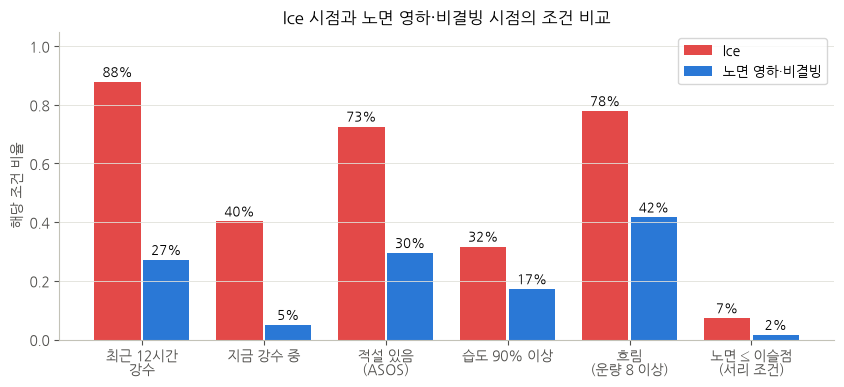

In [7]:
shares = pd.DataFrame({
    "최근 12시간\n강수": [(ice_m["강수시간12h"] > 0).mean(), (cold_m["강수시간12h"] > 0).mean()],
    "지금 강수 중": [(ice_m["aws_rain"] >= 1).mean(), (cold_m["aws_rain"] >= 1).mean()],
    "적설 있음\n(ASOS)": [(ice_m["snow"] > 0).mean(), (cold_m["snow"] > 0).mean()],
    "습도 90% 이상": [(ice_m["aws_rh"] >= 90).mean(), (cold_m["aws_rh"] >= 90).mean()],
    "흐림\n(운량 8 이상)": [(ice_m["cloud"] >= 8).mean(), (cold_m["cloud"] >= 8).mean()],
    "노면 ≤ 이슬점\n(서리 조건)": [(ice_m["노면-이슬점"] <= 0).mean(), (cold_m["노면-이슬점"] <= 0).mean()],
}, index=["Ice", "영하·비결빙"]).T
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(shares))
ax.bar(x - 0.2, shares["Ice"], width=0.38, color=PALETTE[7], label="Ice")
ax.bar(x + 0.2, shares["영하·비결빙"], width=0.38, color=PALETTE[0], label="노면 영하·비결빙")
for i, (a, b) in enumerate(zip(shares["Ice"], shares["영하·비결빙"])):
    ax.text(i - 0.2, a + 0.02, f"{a:.0%}", ha="center", fontsize=9)
    ax.text(i + 0.2, b + 0.02, f"{b:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, shares.index)
ax.set_ylim(0, 1.05)
ax.set_ylabel("해당 조건 비율")
ax.set_title("Ice 시점과 노면 영하·비결빙 시점의 조건 비교")
ax.legend()
ax.grid(axis="x", visible=False)
plt.show()

- **Ice의 88%는 최근 12시간 안에 강수가 있었고**(영하·비결빙은 27%), 40%는 강수가 오는 도중이었다.
- **Ice의 73%는 주변 ASOS에 적설이 있을 때** 나왔다(영하·비결빙 30%).
- 노면이 이슬점보다 낮은 서리 조건은 Ice의 7%뿐이다. 이 지역 고속도로 결빙은 **서리보다 눈·비가 온 뒤 얼어붙는 경우**가 대부분이다.
  결빙 경로별 분류는 13-2, 관측소 자체 이슬점으로 본 서리 조건은 13-3에 있다.
- 기온·노면온도는 오히려 Ice 쪽이 높다(노면 중앙값 -1.6 vs -2.8°C). 강수가 있을 때는 흐리고 덜 춥기 때문이다.
  결빙 판단에서 온도는 "0°C 근처 이하"라는 필요조건이고, 결정적인 것은 수분 공급이다.

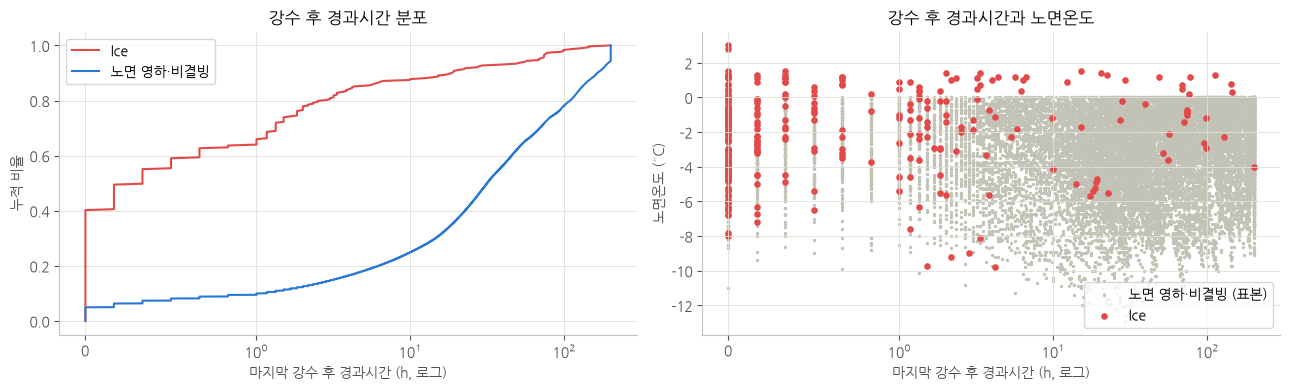

Ice: 강수 후 경과시간 중앙값 0.3 h, 75% 1.8 h
영하·비결빙: 중앙값 31.5 h


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for data, color, label in [(ice_m, PALETTE[7], "Ice"), (cold_m, PALETTE[0], "노면 영하·비결빙")]:
    v = np.sort(data["강수후경과h"].dropna().clip(upper=200))
    axes[0].plot(v, np.arange(1, len(v) + 1) / len(v), color=color, label=label)
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_xlabel("마지막 강수 후 경과시간 (h, 로그)")
axes[0].set_ylabel("누적 비율")
axes[0].set_title("강수 후 경과시간 분포")
axes[0].legend()
sample = cold_m.sample(20000, random_state=0)
axes[1].scatter(sample["강수후경과h"].clip(upper=200), sample["rst"], s=2, color="#c3c2b7", label="노면 영하·비결빙 (표본)")
axes[1].scatter(ice_m["강수후경과h"].clip(upper=200), ice_m["rst"], s=14, color=PALETTE[7], label="Ice")
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set_xlabel("마지막 강수 후 경과시간 (h, 로그)")
axes[1].set_ylabel("노면온도 (°C)")
axes[1].set_title("강수 후 경과시간과 노면온도")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()
print("Ice: 강수 후 경과시간 중앙값", ice_m["강수후경과h"].median().round(1), "h, 75%", ice_m["강수후경과h"].quantile(0.75).round(1), "h")
print("영하·비결빙: 중앙값", cold_m["강수후경과h"].median().round(1), "h")

Ice의 절반은 강수 후 20분 안에, 75%는 2시간 안에 나온다. 영하·비결빙 시간은 마지막 강수 후 하루 넘게(중앙값 31시간) 지난 경우가 많다.
**"최근 강수 + 노면 영하"가 결빙의 핵심 조합**이다.

### 6-3. 풍향

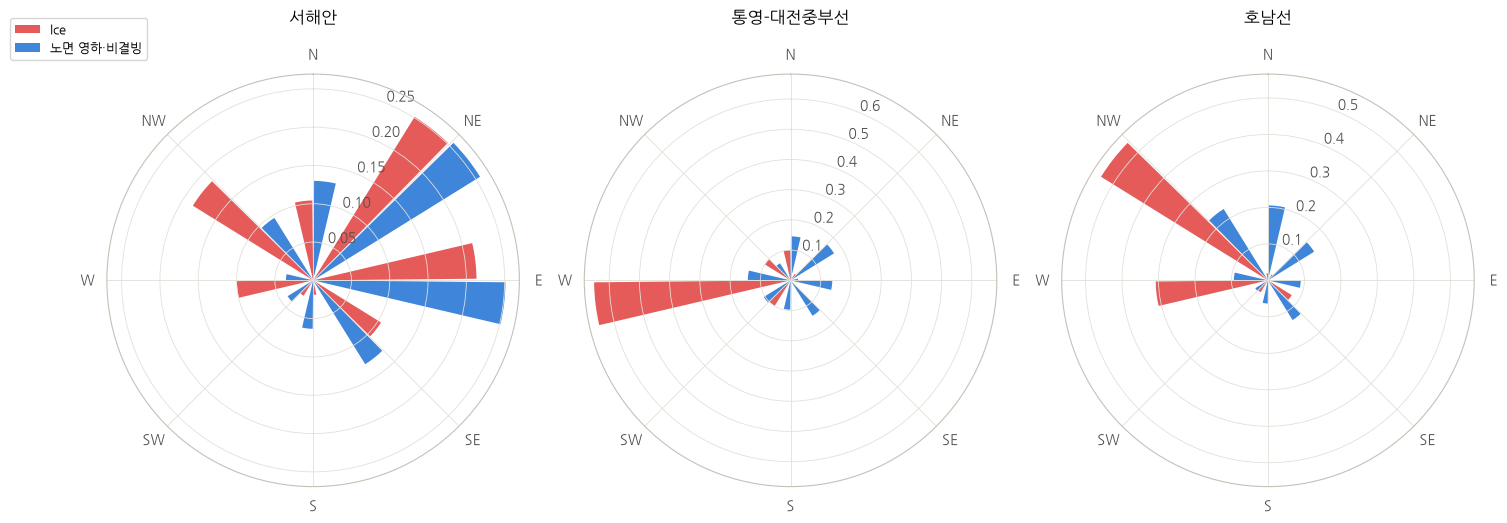

aws_wd,N,NE,E,SE,S,SW,W,NW
노선,,,,,,,,
서해안,0.10,0.25,0.21,0.10,0.02,0.02,0.10,0.18
통영-대전중부선,0.10,0.02,0.02,0.00,0.00,0.10,0.65,0.10
호남선,0.02,0.02,0.00,0.08,0.00,0.04,0.31,0.54


In [9]:
SECTORS = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]


def sector(deg):
    return pd.cut((deg + 22.5) % 360, np.arange(0, 361, 45), labels=SECTORS, right=False)


fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw={"projection": "polar"})
theta = np.radians(np.arange(0, 360, 45))
for ax, route in zip(axes, config.TARGET_ROUTES):
    for data, color, label, off in [(ice_m, PALETTE[7], "Ice", -0.12), (cold_m, PALETTE[0], "노면 영하·비결빙", 0.12)]:
        dd = data[data["노선"] == route]
        freq = sector(dd["aws_wd"]).value_counts(normalize=True).reindex(SECTORS).fillna(0)
        ax.bar(theta + off, freq.values, width=0.22, color=color, label=label, alpha=0.9)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_xticks(theta, SECTORS)
    ax.set_title(route, pad=18)
axes[0].legend(loc="upper left", bbox_to_anchor=(-0.25, 1.15), fontsize=9)
plt.tight_layout()
plt.show()
pd.crosstab(ice_m["노선"], sector(ice_m["aws_wd"]), normalize="index").reindex(columns=SECTORS).round(2)

- 호남선·통영-대전중부선 Ice는 **서풍·북서풍**일 때 집중된다(각 85%, 75% 안팎). 겨울 북서 계절풍이 서해 상공에서 눈구름을 만들어
  내륙으로 들여보내는 전형적인 호남 지방 강설 패턴과 맞는다.
- 서해안선은 북동·동풍 비율이 높다. 강설 뒤 육지 쪽에서 찬 공기가 흘러나오는 밤 시간에 Ice가 많기 때문으로 보인다(5-4의 야간 집중).

## 7. 두 겨울 비교와 기상 현상

### 7-1. ASOS 현상번호

`현상번호(국내식)`은 여러 현상의 2자리 코드를 이어 붙인 값이다 (예: `1905` = 19 박무 + 05 눈, `60501` = 06 진눈깨비 + 05 눈 + 01 비).
앞자리 0이 빠져 있으므로 자릿수를 짝수로 맞춘 뒤 2자리씩 나눈다.

In [10]:
WX = {1: "비", 2: "이슬비", 3: "착빙성의 비", 4: "소낙비", 5: "눈", 6: "진눈깨비", 8: "소낙눈", 10: "싸락눈", 12: "어는비",
      13: "싸락우박", 16: "안개", 19: "박무", 40: "연무", 42: "황사"}


def parse_wx(v):
    if pd.isna(v):
        return []
    s = str(int(v))
    s = "0" + s if len(s) % 2 else s
    return [int(s[i:i + 2]) for i in range(0, len(s), 2)]


asos["wx"] = asos["현상번호(국내식)"].apply(parse_wx)
wx_counts = pd.Series([c for codes in asos["wx"] for c in codes]).value_counts()
pd.DataFrame({"현상": wx_counts.index.map(lambda c: WX.get(c, "?")), "시간 수": wx_counts.values}, index=wx_counts.index)

,현상,시간 수
19,박무,762
1,비,371
5,눈,296
40,연무,222
6,진눈깨비,29
16,안개,22
2,이슬비,18
8,소낙눈,8
10,싸락눈,7
42,황사,6


In [11]:
SNOW_CODES, RAIN_CODES, FREEZING_CODES = {5, 6, 8, 10}, {1, 2, 4}, {3, 7, 12}
asos["눈"] = asos["wx"].apply(lambda c: bool(SNOW_CODES & set(c)))
asos["비"] = asos["wx"].apply(lambda c: bool(RAIN_CODES & set(c)))
asos["어는비"] = asos["wx"].apply(lambda c: bool(FREEZING_CODES & set(c)))
print("어는비·착빙성 비 관측 시간:", int(asos["어는비"].sum()))

어는비·착빙성 비 관측 시간: 0


2년 동안 10개 ASOS에서 착빙성의 비·어는비는 한 번도 관측되지 않았다. 결빙의 수분원은 **눈(진눈깨비 포함)과 비**이다.

### 7-2. 겨울별 비교

In [12]:
asos["date"] = asos["time"].dt.normalize()
asos["winter"] = np.where(asos["time"] < "2025-06-01", "2024-25", "2025-26")
day_reg = asos.groupby(["winter", "date"]).agg(평균기온=("기온(°C)", "mean"), 최저기온=("기온(°C)", "min"),
                                               강수=("강수량(mm)", "sum"), 최대적설=("적설(cm)", "max"),
                                               눈관측=("눈", "any"), 비관측=("비", "any"))
winter_tbl = day_reg.groupby("winter").agg(
    평균기온=("평균기온", "mean"), 최저기온_영하5도_날=("최저기온", lambda s: (s < -5).sum()),
    최저기온_영하10도_날=("최저기온", lambda s: (s < -10).sum()), 강수량_10개소평균=("강수", lambda s: s.sum() / 10),
    적설_있는_날=("최대적설", lambda s: (s > 0).sum()), 최대적설=("최대적설", "max"), 눈_관측일=("눈관측", "sum"),
    비_관측일=("비관측", "sum")).T
rw_w = rwis.groupby("winter").agg(Ice=("ice", "sum"), Snow상태=("state", lambda s: (s == 3).sum()),
                                  결빙관련상태=("state", lambda s: s.isin([3, 4, 13, 15]).sum()),
                                  노면영하비율=("rst", lambda s: (s <= 0).mean())).T
pd.concat([winter_tbl, rw_w]).round(2)

winter,2024-25,2025-26
평균기온,2.74,3.05
최저기온_영하5도_날,60.00,58.00
최저기온_영하10도_날,18.00,23.00
강수량_10개소평균,148.23,89.35
적설_있는_날,59.00,32.00
최대적설,37.90,15.80
눈_관측일,34.00,20.00
비_관측일,40.00,30.00
Ice,231.00,72.00
Snow상태,1956.00,289.00


- 두 겨울의 **기온은 거의 같다**(평균 2.7 vs 3.0°C, 최저 -5°C 미만인 날 60 vs 58일). 노면 영하 비율도 비슷하다.
- 그러나 **2024-25 겨울은 강수량이 1.7배, 적설일이 59 vs 32일, 최대 적설이 37.9 vs 15.8cm**로 눈이 훨씬 많았다.
- 그 결과 Ice는 231 vs 72건(3.2배), Snow 상태는 1,956 vs 289건이다. **결빙 빈도를 정하는 것은 기온보다 강설**이라는 것을 두 겨울의 대비가 보여 준다.

### 7-3. 일별 기상과 결빙

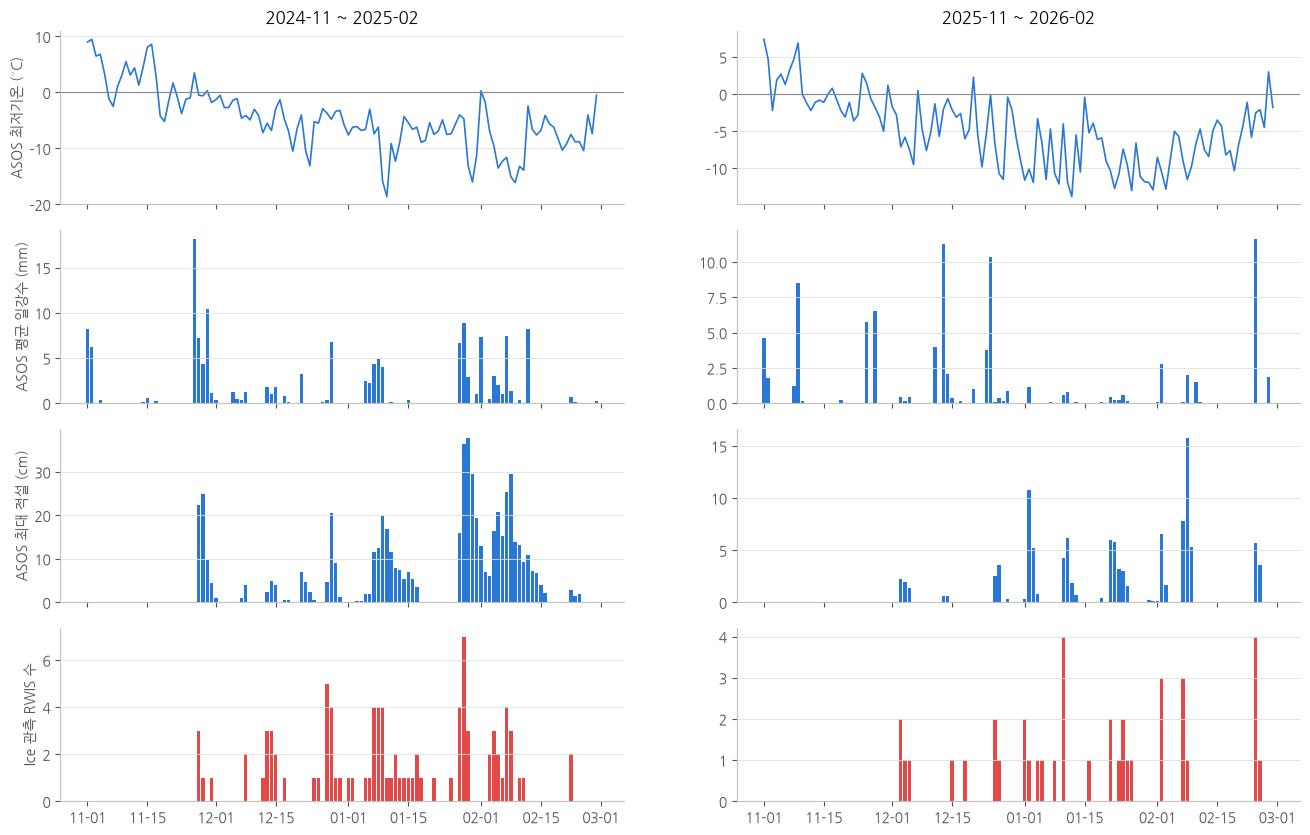

In [13]:
reg = day_reg.reset_index().set_index("date")
fig, axes = plt.subplots(4, 2, figsize=(16, 10), sharex="col", gridspec_kw={"hspace": 0.15})
for col, (start, end) in enumerate(config.PERIODS):
    part = reg.loc[start:end]
    axes[0, col].plot(part.index, part["최저기온"], color=PALETTE[0], linewidth=1.2)
    axes[0, col].axhline(0, color=MUTED, linewidth=0.8)
    axes[1, col].bar(part.index, part["강수"] / 10, color=PALETTE[0], width=0.8)
    axes[2, col].bar(part.index, part["최대적설"].fillna(0), color=PALETTE[0], width=0.8)
    ice_d = ice_by_day.reindex(part.index).fillna(0)
    axes[3, col].bar(part.index, ice_d, color=PALETTE[7], width=0.8)
    axes[0, col].set_title(f"{start[:7]} ~ {end[:7]}")
    axes[3, col].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
for row, label in enumerate(["ASOS 최저기온 (°C)", "ASOS 평균 일강수 (mm)", "ASOS 최대 적설 (cm)", "Ice 관측 RWIS 수"]):
    axes[row, 0].set_ylabel(label)
    for col in range(2):
        axes[row, col].grid(axis="x", visible=False)
plt.show()

In [14]:
snow_day = reg["최대적설"].fillna(0) > 0
ice_day = reg.index.isin(ice_by_day.index)
cond = pd.crosstab(np.where(snow_day, "적설 있음", "적설 없음"), np.where(ice_day, "Ice 있음", "Ice 없음"))
cond["Ice 있는 날 비율"] = cond["Ice 있음"] / cond.sum(axis=1)
cond.round(2)

col_0,Ice 없음,Ice 있음,Ice 있는 날 비율
row_0,,,
적설 없음,136,13,0.09
적설 있음,35,56,0.62


- Ice가 나온 날은 대부분 강수·적설이 있는 날과 겹친다. 강설 직후 며칠 동안 Ice가 이어지고, 맑고 건조한 한파 기간에는 Ice가 거의 없다.
- 어느 ASOS에서든 적설이 있는 날은 62%의 확률로 어딘가에서 Ice가 나왔고, 적설이 없는 날은 9%였다.

## 8. 기온감률 (표고와 기온)

미관측 지점의 기온을 주변 AWS에서 보간할 때 표고 차를 보정해야 한다. DEM 범위 안의 AWS(섬 제외)로 시각마다
기온-표고 회귀 기울기(기온감률)를 구해 표준값(0.65°C/100m)이 맞는지 본다.

기온감률 계산에 쓴 AWS 28개소, 표고 0~1527m


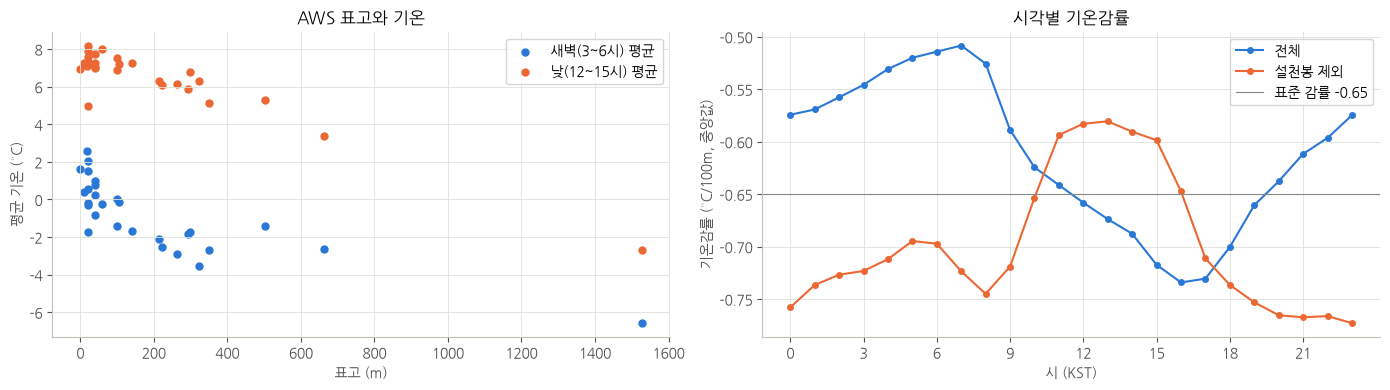

기온감률 중앙값: 전체 -0.61, 설천봉 제외 -0.70 °C/100m
역전(표고가 높을수록 따뜻한 시각) 비율: 0.5%, 설천봉 제외 2.7%


In [15]:
lapse_pt = aws_pt[aws_pt["DEM표고"].notna() & ~aws_pt["stn"].isin([300, 700, 719, 756])]
print(f"기온감률 계산에 쓴 AWS {len(lapse_pt)}개소, 표고 {lapse_pt['DEM표고'].min():.0f}~{lapse_pt['DEM표고'].max():.0f}m")
T_aws = aws_t[lapse_pt["stn"]]


def lapse_rates(temps, elev):
    """시각별 기온-표고 기울기(°C/100m)."""
    X = temps.to_numpy()
    Z = np.where(np.isnan(X), np.nan, elev[None, :])
    zc = Z - np.nanmean(Z, axis=1, keepdims=True)
    tc = X - np.nanmean(X, axis=1, keepdims=True)
    return pd.Series(np.nanmean(zc * tc, axis=1) / np.nanmean(zc ** 2, axis=1) * 100, index=temps.index)


lapse_all = lapse_rates(T_aws, lapse_pt["DEM표고"].to_numpy())
no_peak = lapse_pt["stn"] != 314
lapse_np = lapse_rates(T_aws.loc[:, no_peak.to_numpy()], lapse_pt.loc[no_peak, "DEM표고"].to_numpy())
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
mean_t = T_aws.mean()
night, day = T_aws[T_aws.index.hour.isin([3, 4, 5, 6])].mean(), T_aws[T_aws.index.hour.isin([12, 13, 14, 15])].mean()
axes[0].scatter(lapse_pt["DEM표고"], night, s=25, color=PALETTE[0], label="새벽(3~6시) 평균")
axes[0].scatter(lapse_pt["DEM표고"], day, s=25, color=PALETTE[1], label="낮(12~15시) 평균")
axes[0].set_xlabel("표고 (m)")
axes[0].set_ylabel("평균 기온 (°C)")
axes[0].set_title("AWS 표고와 기온")
axes[0].legend()
for s, color, label in [(lapse_all, PALETTE[0], "전체"), (lapse_np, PALETTE[1], "설천봉 제외")]:
    axes[1].plot(range(24), s.groupby(s.index.hour).median(), color=color, marker="o", markersize=4, label=label)
axes[1].axhline(-0.65, color=MUTED, linewidth=0.8, label="표준 감률 -0.65")
axes[1].set_xticks(range(0, 24, 3))
axes[1].set_xlabel("시 (KST)")
axes[1].set_ylabel("기온감률 (°C/100m, 중앙값)")
axes[1].set_title("시각별 기온감률")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"기온감률 중앙값: 전체 {lapse_all.median():.2f}, 설천봉 제외 {lapse_np.median():.2f} °C/100m")
print(f"역전(표고가 높을수록 따뜻한 시각) 비율: {(lapse_all > 0).mean():.1%}, 설천봉 제외 {(lapse_np > 0).mean():.1%}")

- 지역 전체로 본 기온감률은 -0.6 ~ -0.7°C/100m로 **표준값(-0.65)과 거의 같다.** 02-2의 고도 보정은 이 값을 쓴다.
- 설천봉을 빼면 밤 감률이 더 가파르다(-0.77). 해발 200~500m 내륙 분지(진안, 동향, 무주)가 밤에 특히 차가워지기 때문이다.
  반대로 설천봉을 넣으면 밤 감률이 완만해진다(-0.51). 산 정상은 밤에 골짜기에 고이는 냉기층 위에 있어 상대적으로 덜 차갑다.
  표고가 높을수록 오히려 따뜻한 지역 규모의 기온 역전은 드물다(설천봉 포함 0.5%, 제외 3% 안팎).
  다만 골짜기 바닥의 국지적 냉기호는 AWS 간격으로는 잡히지 않는다.
- Chapman et al.(2001)은 대기 안정도에 따라 감률을 0~9°C/km로 바꾸어 쓴다 (0-3). 이 지역에서도 그런지 13-5에서 확인한다.

## 9. 사례 분석: 2025-01-27 ~ 29

7개 RWIS에서 같은 날 Ice가 나온 2025-01-28 전후를 자세히 본다.

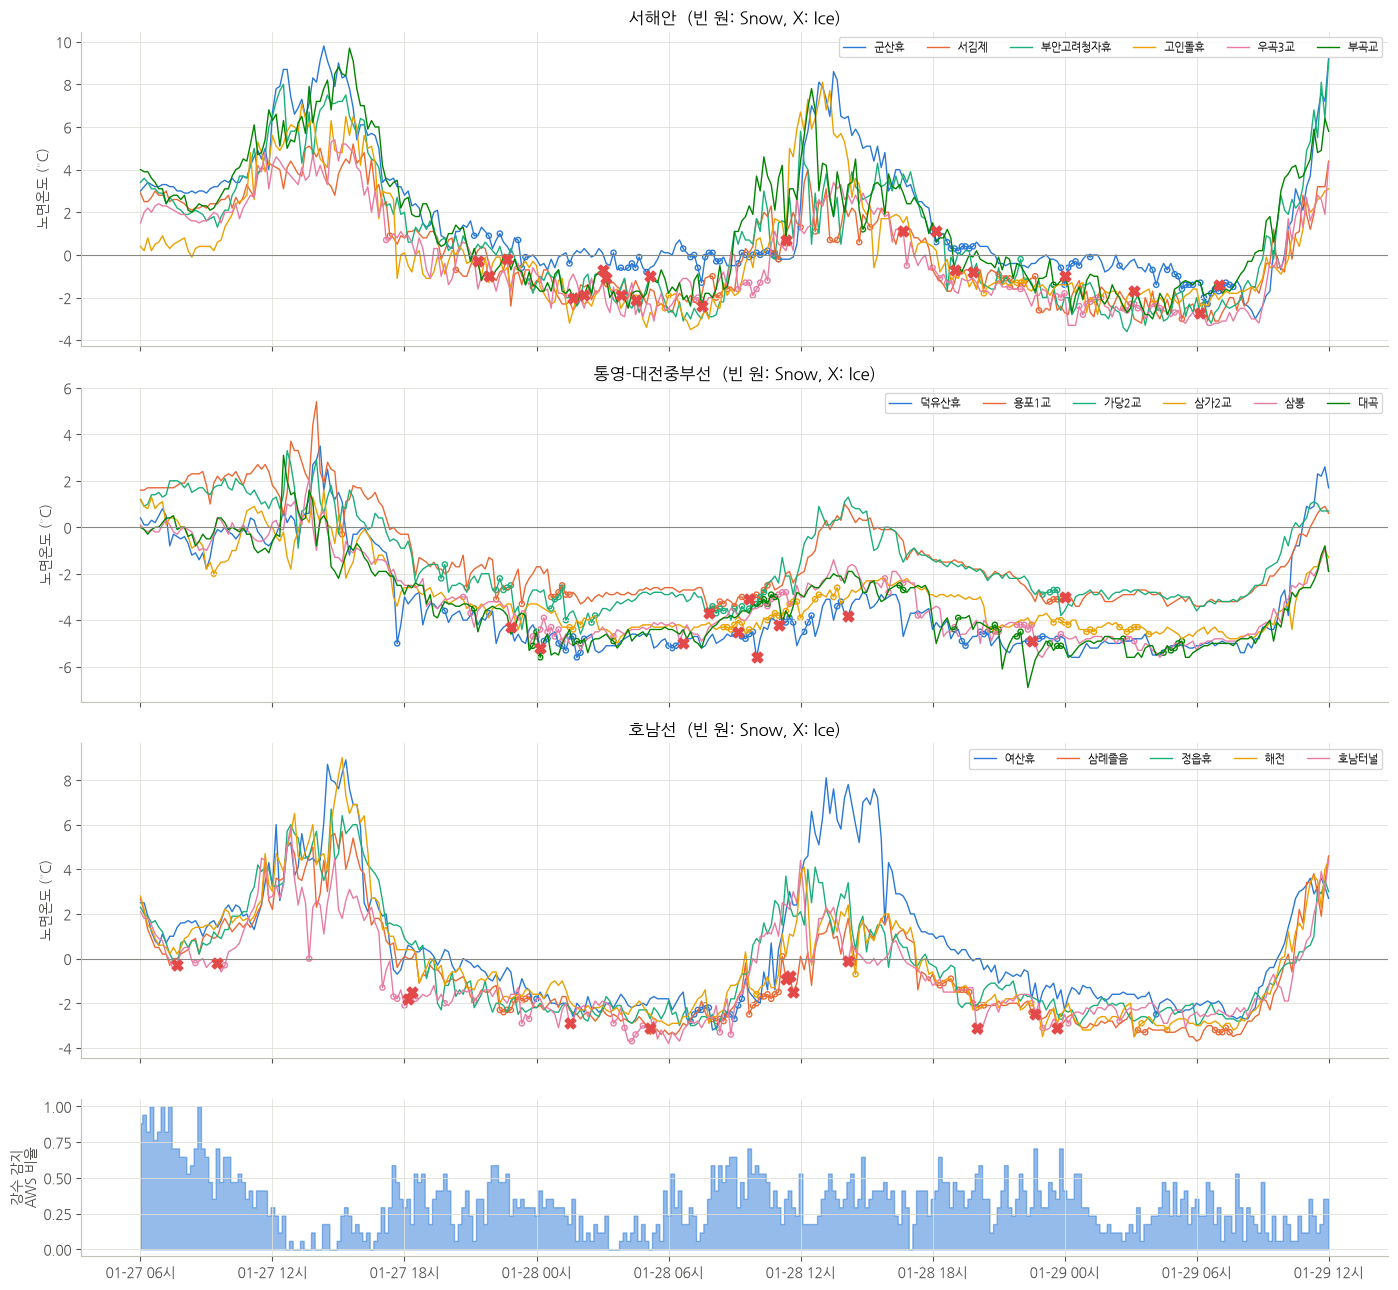

{'고창': 7.2, '고창군': 12.8, '군산': 8.4, '남원': 12.6, '부안': 13.6, '순창군': 20.3, '임실': 37.9, '장수': 26.3, '전주': 21.2, '정읍': nan}


In [16]:
c0, c1 = pd.Timestamp("2025-01-27 06:00"), pd.Timestamp("2025-01-29 12:00")
case = m[m["time"].between(c0, c1)]
fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True, gridspec_kw={"height_ratios": [3, 3, 3, 1.5]})
for ax, route in zip(axes[:3], config.TARGET_ROUTES):
    for i, stn in enumerate(st_info.index[st_info["노선"] == route]):
        g = case[case["stn"] == stn]
        ax.plot(g["time"], g["rst"], color=PALETTE[i], linewidth=1, label=st_info.loc[stn, "지점명"].replace("(도)", ""))
        snow_t = g[g["state"] == 3]
        ice_t = g[g["state"] == 4]
        ax.scatter(snow_t["time"], snow_t["rst"], edgecolors=PALETTE[i], marker="o", s=14, facecolors="none")
        ax.scatter(ice_t["time"], ice_t["rst"], color=PALETTE[7], marker="X", s=60, zorder=5)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_ylabel("노면온도 (°C)")
    ax.set_title(f"{route}  (빈 원: Snow, X: Ice)")
    ax.legend(ncol=6, fontsize=8, loc="upper right")
rain_frac = case.groupby("time")["aws_rain"].mean()
axes[3].fill_between(rain_frac.index, rain_frac.values, step="mid", color=PALETTE[0], alpha=0.5)
axes[3].set_ylabel("강수 감지\nAWS 비율")
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H시"))
plt.tight_layout()
plt.show()
print(asos[asos["time"].between(c0, c1)].groupby("지점명")["적설(cm)"].max().to_dict())

- 1월 27일 아침 강한 강수 뒤 29일까지 약한 강수가 간헐적으로 이어진다. 27일 저녁 노면이 0°C 아래로 내려가면서 여러 관측소가
  Snow 상태가 되고, Ice가 산발적으로 나온다. 28일 낮에 햇빛으로 노면이 영상이 되었다가 밤에 다시 얼면서 Ice가 다시 나온다.
- Ice는 노면이 가장 차가운 시점에 몰리지 않고, **강수가 이어지는 동안 노면이 영하인 시간 전체에 흩어져** 나온다.
  6장(최근 강수 + 노면 영하)과 5-3(간헐적 판정)의 모습이 그대로 보인다.
- 같은 노선 안에서도 Ice가 나오는 관측소와 Snow만 나오는 관측소가 갈린다. 센서 판정의 차이와 국지 조건이 함께 작용한다.

## 10. 검증 지점 분석

검증 지점 3곳은 학습에서 빼고 성능 평가에만 쓴다. 각 지점과 주변 학습 지점의 관계를 보면 기대 성능을 가늠할 수 있다.

In [17]:
rows = []
for h in HOLDOUT:
    p = pairs[(pairs["a"] == h) | (pairs["b"] == h)].copy()
    p["이웃"] = np.where(p["a"] == h, p["b"], p["a"])
    p = p[~p["이웃"].isin(HOLDOUT)].sort_values("거리").head(3)
    for _, r in p.iterrows():
        rows.append({"검증 지점": st_info.loc[h, "지점명"], "이웃 학습 지점": st_info.loc[r["이웃"], "지점명"],
                     "거리(km)": r["거리"], "표고차(m)": abs(rwis_pt.set_index("stn").loc[h, "DEM표고"]
                                                           - rwis_pt.set_index("stn").loc[r["이웃"], "DEM표고"]),
                     "상관": r["상관"], "편차상관": r["편차상관"], "노면온도 RMSE(°C)": r["RMSE"]})
pd.DataFrame(rows).set_index(["검증 지점", "이웃 학습 지점"]).round(3)

거리(km)  표고차(m)     상관   편차상관  노면온도 RMSE(°C)
검증 지점  이웃 학습 지점                                               
부곡교(도) 부안고려청자휴(도)   3.806   0.000  0.994  0.983          0.935
       정읍휴(도)      14.273   0.000  0.978  0.955          1.680
       고인돌휴(도)     20.200  40.329  0.982  0.954          2.060
삼봉(도)  대곡(도)        1.589  19.156  0.989  0.982          0.992
       덕유산휴(도)     11.590  43.353  0.968  0.920          2.081
       삼가2교(도)     20.411  61.501  0.971  0.943          1.752
해전(도)  삼례졸음(도)      2.382   0.000  0.994  0.986          1.013
       여산휴(도)      16.895  41.337  0.990  0.965          1.075
       서김제(도)      20.968   0.000  0.911  0.834          3.676

In [18]:
train_ids = [s for s in st_info.index if s not in HOLDOUT]
rows = []
for s in st_info.index:
    p = pairs[(pairs["a"] == s) | (pairs["b"] == s)].copy()
    p["이웃"] = np.where(p["a"] == s, p["b"], p["a"])
    p = p[p["이웃"].isin(train_ids)].sort_values("거리").iloc[0]
    rows.append({"stn": s, "지점명": st_info.loc[s, "지점명"], "검증지점": s in HOLDOUT,
                 "최근접 학습 지점": st_info.loc[p["이웃"], "지점명"], "거리(km)": p["거리"], "RMSE(°C)": p["RMSE"]})
nn_rmse = pd.DataFrame(rows).set_index("stn")
print("최근접 학습 지점 노면온도를 그대로 쓸 때 RMSE 평균: 검증 지점",
      round(nn_rmse.loc[nn_rmse["검증지점"], "RMSE(°C)"].mean(), 2),
      "/ 학습 지점(자기 제외)", round(nn_rmse.loc[~nn_rmse["검증지점"], "RMSE(°C)"].mean(), 2))
nn_rmse.sort_values("거리(km)").round(2)

최근접 학습 지점 노면온도를 그대로 쓸 때 RMSE 평균: 검증 지점 0.98 / 학습 지점(자기 제외) 1.71


,지점명,검증지점,최근접 학습 지점,거리(km),RMSE(°C)
stn,,,,,
33411,삼봉(도),True,대곡(도),1.59,0.99
23402,해전(도),True,삼례졸음(도),2.38,1.01
12410,부곡교(도),True,부안고려청자휴(도),3.81,0.93
33206,용포1교(도),False,가당2교(도),4.02,1.57
33409,가당2교(도),False,용포1교(도),4.02,1.57
12103,군산휴(도),False,우곡3교(도),4.67,2.22
12409,우곡3교(도),False,군산휴(도),4.67,2.22
33103,덕유산휴(도),False,삼가2교(도),8.82,1.77
33410,삼가2교(도),False,덕유산휴(도),8.82,1.77


- **검증 지점 3곳 모두 4km 안에 상관 0.99의 학습 지점이 있다**(부곡교-부안고려청자휴 3.8km, 삼봉-대곡 1.6km, 해전-삼례졸음 2.4km).
  최근접 학습 지점의 노면온도를 그대로 써도 RMSE가 약 1°C이다.
- 반면 학습 지점은 (검증 지점을 뺀) 최근접 학습 이웃이 더 멀고, 그 이웃 값을 그대로 쓸 때 RMSE가 1.0~2.2°C(평균 1.7°C)로 크다.
  그래서 학습 지점의 교차검증 오차(03-1)는 검증 지점 오차보다 크게 나온다. 두 숫자를 함께 봐야 실제 미관측 구간의 성능을 가늠할 수 있다.
- Ice는 부곡교에만 있고(64건), 삼봉·해전은 0건이다. 결빙 분류의 지점별 성능은 사실상 부곡교 한 곳이 좌우한다.

## 저장

01-6·01-7(13장)에서 쓰도록 6-1의 결합 자료 `m`(RWIS + 최근접 AWS·ASOS)과 8장의 시각별 기온감률을 저장한다.

In [19]:
m.to_parquet(config.INTERIM_DIR / "rwis_weather.parquet", index=False)
pd.DataFrame({"전체": lapse_all, "설천봉 제외": lapse_np}).to_parquet(config.INTERIM_DIR / "lapse_rates.parquet")
for name in ["rwis_weather.parquet", "lapse_rates.parquet"]:
    print(f"{name:24s} {(config.INTERIM_DIR / name).stat().st_size / 1e6:7.1f} MB")

rwis_weather.parquet        14.2 MB
lapse_rates.parquet          1.0 MB
